<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lição 02 · Machine Learning: fundamentos</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">05 · Reinforcement Learning: mini-projeto de Q-learning</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Mini-projeto de Q-learning</p>
</div>

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/02-machine-learning-fundamentals/blob/main/04_reinforcement_learning/notebooks/05_Reinforcement_Learning_Project.ipynb) [![Slides](https://img.shields.io/badge/slides-Lição_02-ffd43b)](https://the-ai-learning-hub.github.io/02-machine-learning-fundamentals/#rl)

## 🎯 Objetivos de aprendizagem

No fim deste notebook és capaz de:

- descrever um problema como um MDP (estados, ações, recompensas, desconto) com um exemplo concreto;
- calcular um retorno descontado e uma atualização de Q-learning à mão, e verificá-los em código;
- treinar um agente com Q-learning e ler a tabela Q e a política *greedy* em vários momentos do treino;
- avaliar com rigor (ε = 0, separado do treino, várias seeds, ambiente com ruído);
- reconhecer e reproduzir *reward hacking* e discutir *reward shaping*.

**⏱️ Duração estimada:** ≈ 30 min · **📋 Pré-requisitos:** notebooks 01 a 04; ideia de valor esperado · **▶️ Como usar:** executa cada célula com `Shift`+`Enter`, por ordem.

## 📑 Índice

1. [🧭 Business Understanding (compreensão do negócio)](#sec-1)
2. [🔍 Data Understanding: o mundo do agente](#sec-2)
3. [🧹 Data Preparation: formular o MDP e o retorno](#sec-3)
4. [🤖 Modeling (modelação): Q-learning](#sec-4)
5. [📏 Evaluation (avaliação) com rigor](#sec-5)
6. [🚀 Deployment e limites: reward hacking e shaping](#sec-6)
7. [🔭 Extensões](#sec-7)
8. [✏️ Exercícios](#sec-8)
9. [📌 Resumo](#sec-9)
10. [📚 Para saber mais](#sec-10)

<a id="sec-0"></a>

## ⚙️ Preparar o ambiente

In [1]:
# ⚙️ Preparar o ambiente: funciona localmente (VS Code/Jupyter) e no Google Colab
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/02-machine-learning-fundamentals")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/02-machine-learning-fundamentals.git",
                        str(ROOT)], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

try:  # o Colab já traz tudo; localmente usa `uv sync` (ver README)
    import sklearn, seaborn  # noqa: F401
except ImportError:  # plano B: instala as dependências declaradas no pyproject.toml
    import tomllib
    deps = tomllib.loads((ROOT / "pyproject.toml").read_text(encoding="utf-8"))["project"]["dependencies"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *deps], check=True)

sys.path.insert(0, str(ROOT))
print("Raiz do projeto:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Raiz do projeto: 02-machine-learning-fundamentals (local)


> 💡 **Dica:** no Colab não tens de instalar nada. Localmente, corre `uv sync` na raiz do projeto e escolhe o kernel `.venv` no Jupyter/VS Code.
>
> 📖 **Primeira vez?** Se algum termo (dataset, *feature*, alvo, modelo, treinar, prever, erro, *overfitting*) for novo, lê o [Vocabulário do notebook 01](../../01_supervised_learning/notebooks/01_CRISP-DM_House_Prices.ipynb#vocab). Cada notebook volta a explicar os termos novos na primeira vez que aparecem.

<a id="sec-1"></a>

# 1. 🧭 Business Understanding (compreensão do negócio)

Em **reinforcement learning** (RL, aprendizagem por reforço) não há exemplos com a resposta certa: há um **agente** que age num **ambiente**, recebe **recompensas** e tem de descobrir sozinho, por tentativa e erro, uma **política** (o que fazer em cada situação).

**O problema.** Um robô num armazém (um mapa 5×6) tem de ir da posição de partida **S** até ao objetivo **G**, sem cair na **lava L** (zonas proibidas) e sem se encostar a paredes, gastando o menos possível.

| Pergunta de negócio | Resposta |
|---|---|
| O que queremos que o agente faça? | chegar a G, de forma segura e rápida |
| O que é **sucesso**? | **taxa de sucesso** (episódios que terminam em G) e retorno por episódio em avaliação |
| O que é **falha**? | cair em L, ou esgotar os 100 passos |
| Que sinal dá o agente ao ambiente? | só a recompensa: −1 por passo, +20 no objetivo, −20 na lava |

> ⚠️ **Cuidado:** a recompensa é um **proxy** do que realmente queremos. Se o proxy tiver um atalho, o agente encontra-o (secção 6).

### 📖 Palavras que vão aparecer (mini-glossário)

Os termos básicos (dataset, *feature*, modelo, treinar, prever, erro) estão no [Vocabulário do notebook 01](../../01_supervised_learning/notebooks/01_CRISP-DM_House_Prices.ipynb#vocab). Aqui ficam os do reforço; cada um volta a ser explicado quando aparece:

| Termo | Em palavras simples |
|---|---|
| **agente** | quem decide e age (aqui, o robô no mapa) |
| **ambiente** | o mundo onde o agente age e que lhe responde (o mapa e as suas regras) |
| **estado** ($s$) | a situação atual do agente (aqui, a célula onde está, numerada de 0 a 29) |
| **ação** ($a$) | o que o agente pode fazer (↑ → ↓ ←) |
| **recompensa** ($r$) | o número que o ambiente devolve depois de cada ação (−1, +20, −20) |
| **política** | a regra "em cada estado, faço esta ação" (o que queremos aprender) |
| **episódio** | uma tentativa completa, do início até ao objetivo, à lava ou ao limite de passos |
| **retorno** ($G$) | a soma das recompensas (com desconto) de um episódio |
| **tabela Q** | uma tabela com uma linha por estado e uma coluna por ação, com a nota que o agente dá a cada ação |
| **ε-greedy** | com probabilidade ε o agente tenta uma ação ao acaso (explora); senão escolhe a de melhor nota (*greedy*, "gananciosa") |
| $\alpha$ e $\gamma$ | $\alpha$ = quanto ajusta a nota em cada passo; $\gamma$ = quanto valoriza o futuro (0 a 1) |

### 💬 Discussão — Sucesso: retorno ou taxa de sucesso?

Estamos a medir o agente pelo **retorno** (soma das recompensas) e pela **taxa de sucesso** (chegou a G?). Em que situação um número engana e o outro não?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

O retorno é o que o agente **otimiza**; a taxa de sucesso é o que **nós queremos**. Normalmente andam juntos, e por isso medimos os dois. Na secção 6 vais ver um agente com retorno de avaliação **494** e taxa de sucesso **0 %**: a métrica que ele otimiza subiu e a tarefa falhou. Num projeto real, o indicador de negócio (sucesso) tem de ser medido à parte, e nunca só através da recompensa que desenhámos.
</details>

<a id="sec-2"></a>

# 2. 🔍 Data Understanding: o mundo do agente

## 🗂️ Conhecer o mundo do agente

Aqui **não há ficheiro de dados**: os "dados" são a **experiência** que o agente gera ao tentar. Por isso conhecer os dados é conhecer o **ambiente**:

| | |
|---|---|
| **O que é** | um mapa de 5 linhas × 6 colunas (30 células), inventado para a aula e implementado em `src/rl_utils.py` |
| **Estado** | o número da célula onde o agente está (0 a 29, linha a linha; o início é o 24 e o objetivo o 5) |
| **Ações** | 4: ↑ → ↓ ← (bater numa parede ou na borda não move o agente) |
| **Recompensas** | −1 por cada passo; +20 ao chegar ao objetivo (G); −20 ao cair na lava (L) |
| **Fim de um episódio** | chegar a G, cair em L, ou 100 passos |
| **Aleatoriedade** | por omissão nenhuma; com `slip=0.1`, 10 % das ações saem ao acaso |

**Seeds:** Q-learning com `seed=0` (*seed* = número que fixa o "acaso" para o resultado ser repetível); avaliação com várias seeds.

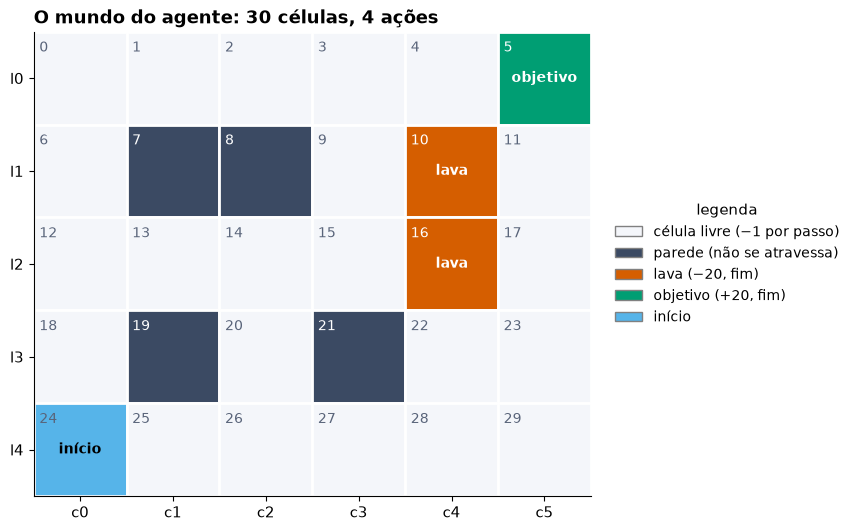

estados = 30 | ações = 4 (0=↑, 1=→, 2=↓, 3=←) | máx. 100 passos
recompensas: passo -1.0, objetivo +20, lava -20 | tabela Q: 30 × 4 = 120 números


In [2]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display

from src.plotting import apply_style, PALETTE, CYCLE, MARKERS
from src.rl_utils import (GridWorld, DEFAULT_LAYOUT, COIN_LAYOUT, ARROWS, q_learning, evaluate, greedy_path,
                          greedy_action, moving_average, epsilon_schedule, plot_q_values)

apply_style()

# 🖌️ Auxiliar de gráficos: números à portuguesa (vírgula decimal, espaço nos milhares) e letra ≥ 10 pt
import re
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter
from src.plotting import fmt_pt


def _decimals(axis):
    """Casas decimais necessárias para os valores dos ticks (0 a 3; em escala log, as que o menor tick pede)."""
    locs = np.asarray(axis.get_majorticklocs(), dtype=float)
    if axis.get_scale() == "log":
        locs = np.abs(locs[locs != 0])
        return int(min(4, max(0, np.ceil(-np.log10(locs.min()))))) if locs.size else 0
    for d in range(4):
        if np.allclose(locs, np.round(locs, d), atol=1e-9):
            return d
    return 3


def finish(fig):
    """Formata os números à portuguesa e garante letra >= 10 pt."""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if not isinstance(axis.get_major_formatter(), (mpl.ticker.ScalarFormatter, mpl.ticker.LogFormatterSciNotation, mpl.ticker.LogFormatter)):
                continue
            if axis.get_scale() == "log":
                axis.set_major_locator(mpl.ticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
                axis.set_minor_formatter(mpl.ticker.NullFormatter())
                axis.set_major_formatter(FuncFormatter(lambda v, _: fmt_pt(v, 0 if v >= 1 else int(np.ceil(-np.log10(v) - 1e-9)) if v > 0 else 0)))
            else:
                if getattr(axis, "_pt_int", False):
                    axis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
                axis.set_major_formatter(FuncFormatter(lambda v, _, a=axis: fmt_pt(v, _decimals(a))))
    for text in fig.findobj(mpl.text.Text):
        s = text.get_text()
        if re.search(r"\d\.\d", s):
            text.set_text(re.sub(r"(\d)\.(\d)", r"\1,\2", s))
        if text.get_fontsize() < 10:
            text.set_fontsize(10)


_show = plt.show


def _show_pt(*args, **kwargs):
    for num in plt.get_fignums():
        finish(plt.figure(num))
    return _show(*args, **kwargs)


plt.show = _show_pt


CELL_COLOURS = {"#": "#3b4a63", "L": PALETTE["red"], "G": PALETTE["green"], "C": PALETTE["orange"], "S": PALETTE["sky"], ".": "#f4f6fa"}

def draw_map(env, ax=None, title=None, path=None, agent=None, legend=False, numbers=False):
    """Desenha o mapa: paredes, lava, objetivo, moeda, início; opcionalmente o caminho e a posição do agente."""
    ax = ax or plt.gca()
    for r in range(env.n_rows):
        for c in range(env.n_cols):
            kind = str(env.grid[r, c])
            ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=CELL_COLOURS[kind], edgecolor="white", lw=2))
            label = {"L": "lava", "G": "objetivo", "C": "moeda", "S": "início"}.get(kind, "")
            if label:
                ax.text(c, r, label, ha="center", va="center", fontsize=10, fontweight="bold",
                        color="black" if kind in "CS" else "white")
            if numbers:
                ax.text(c - 0.44, r - 0.4, str(r * env.n_cols + c), ha="left", va="top", fontsize=10, color="#59647a" if kind in ".S" else "white")
    if legend:
        names = {".": "célula livre (−1 por passo)", "#": "parede (não se atravessa)", "L": "lava (−20, fim)", "G": "objetivo (+20, fim)",
                 "S": "início", "C": "moeda (+5, não desaparece)"}
        present = [k for k in names if k in set(env.grid.ravel())]
        ax.legend(handles=[Rectangle((0, 0), 1, 1, facecolor=CELL_COLOURS[k], edgecolor="grey", label=names[k]) for k in present],
                  loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10, frameon=False, title="legenda")
    if path is not None:
        rows, cols = np.divmod(np.array(path), env.n_cols)
        ax.plot(cols, rows, color=PALETTE["navy"], lw=2.5, ls="--", marker="o", ms=5)
    if agent is not None:
        r, c = divmod(agent, env.n_cols)
        ax.plot(c, r, marker="o", ms=26, color=PALETTE["purple"], mec="black", mew=1.5, zorder=5)
    ax.set(xlim=(-0.5, env.n_cols - 0.5), ylim=(env.n_rows - 0.5, -0.5), aspect="equal")
    ax.set_xticks(range(env.n_cols), [f"c{c}" for c in range(env.n_cols)]); ax.set_yticks(range(env.n_rows), [f"l{r}" for r in range(env.n_rows)])
    ax.grid(False)
    if title: ax.set_title(title)
    return ax

env = GridWorld()
fig, ax = plt.subplots(figsize=(9.5, 5.2), layout="constrained")
draw_map(env, ax, "O mundo do agente: 30 células, 4 ações", legend=True, numbers=True)
finish(fig); plt.show()
print(f"estados = {env.n_states} | ações = {env.n_actions} ({', '.join(f'{a}={ARROWS[a]}' for a in range(4))}) | máx. {env.max_steps} passos")
print(f"recompensas: passo {env.step_reward}, objetivo +{env.goal_reward:.0f}, lava {env.lava_reward:.0f} | tabela Q: {env.n_states} × {env.n_actions} = {env.n_states * env.n_actions} números")

Cada célula é um **estado** (numerado de 0 a 29, linha a linha: S = 24, G = 5). Em cada estado há 4 **ações** (↑ → ↓ ←). Bater numa parede ou na borda não move o agente, mas **custa um passo** (−1). O episódio termina no objetivo, na lava ou ao fim de 100 passos.

### 💬 Discussão — O que vê o agente?

O agente só conhece o número da célula onde está e a recompensa que recebeu. Que informação **não** tem? O que muda se o chão escorregar (10 % das ações saem ao acaso)?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Não vê o mapa nem sabe onde está a lava: tem de **descobrir** pelas consequências. Só conhece "estado → ação → recompensa → novo estado". Se o chão escorregar (`slip=0.1`), a mesma ação pode ter resultados diferentes e o ambiente deixa de ser determinístico: uma política ótima passa a ter de ser robusta ao azar (vamos testá-lo na secção 5, com sucesso de 97 %).
</details>

<a id="sec-3"></a>

# 3. 🧹 Data Preparation: formular o MDP e o retorno

Formalizamos como um **MDP** (*Markov Decision Process*, processo de decisão de Markov): $(\mathcal S, \mathcal A, P, R, \gamma)$.

| Elemento | Neste mundo |
|---|---|
| Estados $\mathcal S$ | as 30 células |
| Ações $\mathcal A$ | ↑ → ↓ ← |
| Transições $P(s'\mid s,a)$ | andar para a célula vizinha (a menos que seja parede/borda); com `slip` pode sair outra ação |
| Recompensa $R$ | −1 por passo, +20 em G, −20 em L |
| Desconto $\gamma$ | 0,95 |

**Propriedade de Markov:** o futuro depende só do estado atual, não de como lá chegámos.

### Retorno descontado

O que o agente maximiza não é a recompensa de agora, mas o **retorno**: $G_t = r_{t+1} + \gamma\,r_{t+2} + \gamma^2 r_{t+3} + \dots$. O desconto $\gamma<1$ faz com que uma recompensa futura valha menos do que uma imediata. Para o caminho ótimo (8 passos de −1 e depois +20), calcula-se:

In [3]:
gamma = 0.95
rewards = [-1] * 8 + [20]                       # 8 passos custam -1; o 9.º passo chega a G (+20)
G0 = sum(gamma**t * r for t, r in enumerate(rewards))
print(f"retorno SEM desconto (soma simples) = {sum(rewards)}")
print(f"retorno COM γ = {gamma}              = {G0:.3f}")
for g in (0.5, 0.9, 0.99):
    print(f"  com γ = {g:<4}: G₀ = {sum(g**t * r for t, r in enumerate(rewards)):6.2f}")

retorno SEM desconto (soma simples) = 12
retorno COM γ = 0.95              = 6.537
  com γ = 0.5 : G₀ =  -1.91
  com γ = 0.9 : G₀ =   2.91
  com γ = 0.99: G₀ =  10.73


Com γ = 0,95 o caminho ótimo vale ≈ 6,5 visto da partida (contra 12 sem desconto): o +20 está a 9 passos e é descontado, mas o caminho continua a compensar. Com γ pequeno o agente é míope: com γ = 0,5 o retorno descontado até é **negativo** (−1,9), porque o +20 distante quase não pesa; com γ → 1 valoriza o futuro tanto como o presente.

### 💬 Discussão — Formulação: o desenho do MDP

Porque é que o passo custa −1? O que aconteceria ao comportamento do agente se o passo custasse 0?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

O −1 por passo é o que dá **pressa**: sem ele, qualquer caminho até G valeria o mesmo e o agente não teria razão para o preferir curto. (O desconto γ já dá alguma pressa, mas fraca.) O desenho da recompensa **é** a especificação do problema: escolher −1, +20 e −20 é decidir quanto vale chegar ao objetivo, evitar a lava e poupar tempo. Os valores são uma escolha do exemplo, não uma lei da natureza.
</details>

<a id="sec-4"></a>

# 4. 🤖 Modeling (modelação): Q-learning

## 🧠 Como funciona: Q-learning

**Ideia simples.** O agente mantém uma **tabela de notas**: para cada célula e cada direção, "quão boa é esta jogada?". No início todas as notas são 0. Joga, vê o que aconteceu e **corrige a nota** da jogada que fez, aproximando-a do que realmente viu (a recompensa imediata mais a melhor nota da célula seguinte). Com muitas tentativas, as notas boas "propagam-se" do objetivo para trás e o agente passa a escolher, em cada célula, a jogada de nota mais alta.

**Analogia:** um turista num bairro novo que anota "da estação, ir para norte foi bom, para sul foi mau" e vai corrigindo as notas à medida que explora.

**O ciclo de cada passo:** (1) o agente vê o **estado** $s$; (2) escolhe uma **ação** $a$ (às vezes ao acaso: explorar); (3) o ambiente devolve a **recompensa** $r$ e o novo estado $s'$; (4) o agente **atualiza** $Q(s,a)$; (5) repete até o episódio acabar.

**Quando usar:** poucos estados e ações (cabem numa tabela). **Cuidados:** a recompensa tem de descrever bem o que queremos (secção 6); com milhões de estados a tabela deixa de caber (por isso o DQN).

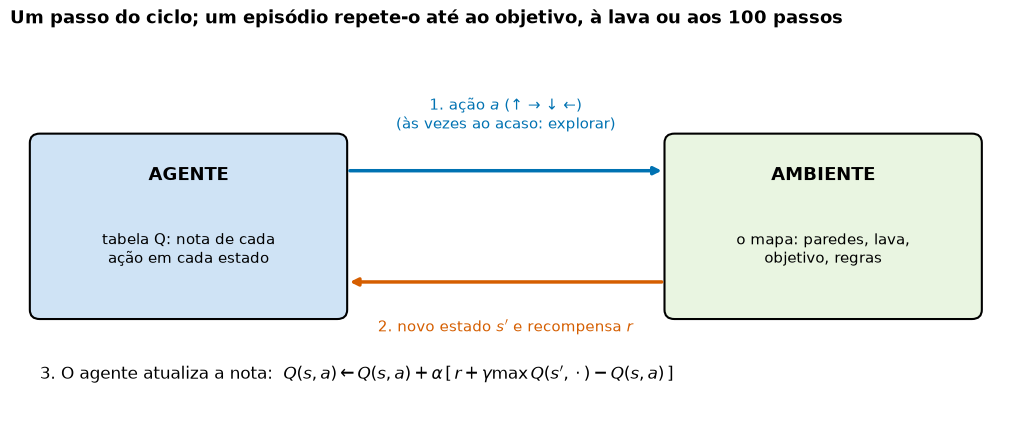

In [4]:
# Mecanismo: o ciclo agente-ambiente
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained"); ax.axis("off"); ax.set(xlim=(0, 10), ylim=(0, 4.2))
for x, title, body, colour in ((0.3, "AGENTE", "tabela Q: nota de cada" + chr(10) + "ação em cada estado", "#cfe3f5"),
                               (6.7, "AMBIENTE", "o mapa: paredes, lava," + chr(10) + "objetivo, regras", "#e9f5e1")):
    ax.add_patch(FancyBboxPatch((x, 1.2), 3.0, 1.8, boxstyle="round,pad=0.1", fc=colour, ec="black", lw=1.5))
    ax.text(x + 1.5, 2.65, title, ha="center", va="center", fontsize=13, fontweight="bold")
    ax.text(x + 1.5, 1.85, body, ha="center", va="center", fontsize=11)
ax.annotate("", xy=(6.6, 2.7), xytext=(3.4, 2.7), arrowprops=dict(arrowstyle="-|>", lw=2.5, color=PALETTE["blue"]))
ax.text(5.0, 3.1, "1. ação $a$ (↑ → ↓ ←)" + chr(10) + "(às vezes ao acaso: explorar)", ha="center", va="bottom", fontsize=11, color=PALETTE["blue"])
ax.annotate("", xy=(3.4, 1.5), xytext=(6.6, 1.5), arrowprops=dict(arrowstyle="-|>", lw=2.5, color=PALETTE["red"]))
ax.text(5.0, 1.1, "2. novo estado $s'$ e recompensa $r$", ha="center", va="top", fontsize=11, color=PALETTE["red"])
ax.text(0.3, 0.45, "3. O agente atualiza a nota:  $Q(s,a) \\leftarrow Q(s,a) + \\alpha\\,[\\,r + \\gamma \\max Q(s',\\cdot) - Q(s,a)\\,]$", fontsize=12)
ax.set_title("Um passo do ciclo; um episódio repete-o até ao objetivo, à lava ou aos 100 passos")
finish(fig); plt.show()

$Q(s,a)$ é o **retorno esperado** se, no estado $s$, o agente fizer $a$ e depois seguir a melhor política. Aprende-se com a **atualização de Q-learning**, depois de cada passo $(s, a, r, s')$:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\Big[\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{alvo}} - Q(s,a)\Big]$$

com $\alpha = 0{,}5$ (taxa de aprendizagem). Se $s'$ é terminal, o alvo é só $r$ (não há futuro). A política é **ε-greedy**: com probabilidade ε explora (ação ao acaso), senão explora o que já sabe (a ação com maior $Q$).

### Uma atualização à mão (com números)

Todos os valores de $Q$ começam a 0. Duas transições perto do objetivo (estado 4 = linha 0, coluna 4; estado 3 = coluna 3):

1. **Estado 4, ação →, chega a G (+20, terminal):** alvo $= 20$; $Q(4,\rightarrow) = 0 + 0{,}5\,(20 - 0) = 10$.
2. **Estado 3, ação →, vai para o estado 4 (−1):** alvo $= -1 + 0{,}95 \cdot \max_a Q(4,a) = -1 + 0{,}95\cdot 10 = 8{,}5$; $Q(3,\rightarrow) = 0 + 0{,}5\,(8{,}5 - 0) = 4{,}25$.

Repara que o valor de G **propagou-se um passo para trás**, descontado. Agora em código:

In [5]:
alpha = 0.5
Q_demo = np.zeros((env.n_states, env.n_actions))

def td_update(Q, s, a, r, s2, terminal):
    """Uma atualização de Q-learning (devolve o alvo)."""
    target = r if terminal else r + gamma * Q[s2].max()
    Q[s, a] += alpha * (target - Q[s, a])
    return target

# transição 1: estado 4, ação → (1)  ->  G
env.reset(); env.state = 4
s2, r, done, outcome = env.step(1)
t1 = td_update(Q_demo, 4, 1, r, s2, outcome in ("goal", "lava"))
print(f"1) s=4, a=→ -> s'={s2}, r={r:+.0f}, terminal={done}: alvo={t1:.2f}, Q(4,→)={Q_demo[4, 1]:.2f}")

# transição 2: estado 3, ação → (1)  ->  estado 4
env.reset(); env.state = 3
s2, r, done, outcome = env.step(1)
t2 = td_update(Q_demo, 3, 1, r, s2, outcome in ("goal", "lava"))
print(f"2) s=3, a=→ -> s'={s2}, r={r:+.0f}, terminal={done}: alvo={t2:.2f}, Q(3,→)={Q_demo[3, 1]:.2f}")
assert abs(Q_demo[4, 1] - 10) < 1e-9 and abs(Q_demo[3, 1] - 4.25) < 1e-9

1) s=4, a=→ -> s'=5, r=+20, terminal=True: alvo=20.00, Q(4,→)=10.00
2) s=3, a=→ -> s'=4, r=-1, terminal=False: alvo=8.50, Q(3,→)=4.25


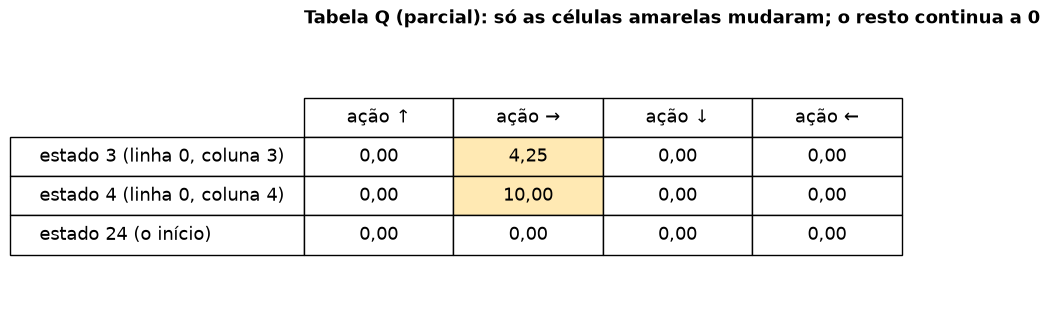

In [6]:
# A tabela Q: uma linha por estado, uma coluna por ação (só mostramos 3 das 30 linhas, depois das 2 atualizações)
rows_shown = [3, 4, 24]
cells = [[fmt_pt(Q_demo[st, a], 2) for a in range(4)] for st in rows_shown]
fig, ax = plt.subplots(figsize=(9, 3.2), layout="constrained"); ax.axis("off")
tab = ax.table(cellText=cells, colLabels=[f"ação {ARROWS[a]}" for a in range(4)],
               rowLabels=["estado 3 (linha 0, coluna 3)", "estado 4 (linha 0, coluna 4)", "estado 24 (o início)"], loc="center", cellLoc="center")
tab.auto_set_font_size(False); tab.set_fontsize(13); tab.scale(1, 2)
tab[(2, 1)].set_facecolor("#ffe9b3"); tab[(1, 1)].set_facecolor("#ffe9b3")   # as duas células atualizadas (→)
ax.set_title("Tabela Q (parcial): só as células amarelas mudaram; o resto continua a 0")
finish(fig); plt.show()

> 🤖 **Ligação à IA:** esta mesma regra (com uma rede neuronal no lugar da tabela) é o **DQN**, que aprendeu a jogar Atari. Sem tabela, mas com a mesma ideia: aproximar $Q$ e atualizar na direção do alvo.

### 💬 Discussão — Modelação: explorar ou aproveitar?

Com ε = 1 o agente age ao acaso; com ε = 0 age só pelo que já sabe. Porque é que começar com ε = 0 seria má ideia neste mapa em que todos os valores Q começam a 0?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Com todos os Q a 0 e ε = 0, o agente escolhe sempre a mesma ação (ou ao acaso entre empates) e só reforça o que lhe deu uma recompensa menos má: pode ficar a bater numa parede ou a seguir um caminho mau sem nunca descobrir G. É o **dilema exploração–aproveitamento**. Por isso usamos ε a decair de 1,0 para 0,05 nos primeiros 60 % do treino: muito ao acaso no início, mais ``a sério'' no fim.
</details>

### Treino: 400 episódios

`q_learning(GridWorld(), episodes=400, seed=0, snapshot_at=(10, 50, 400))` devolve a tabela $Q$ e o histórico (retorno, comprimento, desfecho e ε por episódio), com cópias de $Q$ nos episódios pedidos.

In [7]:
t0 = time.perf_counter()
Q, hist = q_learning(GridWorld(), episodes=400, seed=0, snapshot_at=(10, 50, 400))
print(f"treino de 400 episódios em {time.perf_counter() - t0:.2f} s")
returns = np.array(hist["return"])
success = np.array([o == "goal" for o in hist["outcome"]], dtype=float)
print(f"retorno médio, primeiros 50 episódios: {returns[:50].mean():6.1f}   (PLAN: −57,5)")
print(f"retorno médio, últimos 50 episódios  : {returns[-50:].mean():6.1f}   (PLAN: ≈ 10,8)")
print(f"sucesso nos últimos 50 episódios     : {success[-50:].mean():.0%}   (PLAN: 98 %; ainda há ε = 0,05)")

treino de 400 episódios em 0.07 s


retorno médio, primeiros 50 episódios:  -57.5   (PLAN: −57,5)
retorno médio, últimos 50 episódios  :   10.8   (PLAN: ≈ 10,8)
sucesso nos últimos 50 episódios     : 98%   (PLAN: 98 %; ainda há ε = 0,05)


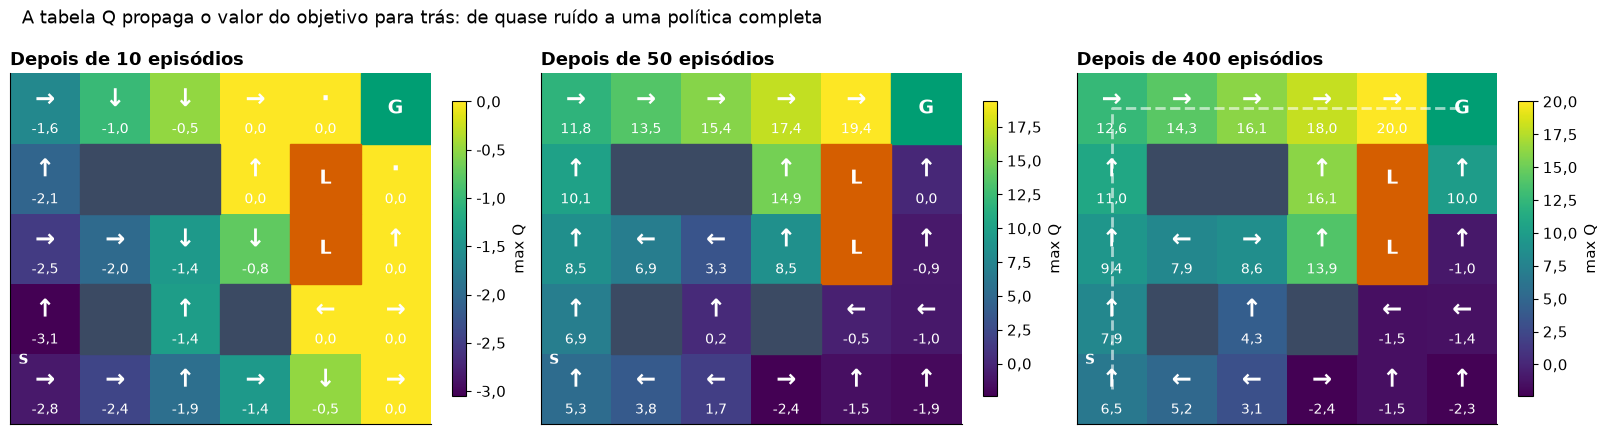

In [8]:
world = GridWorld()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
for ax, ep in zip(axes, (10, 50, 400)):
    plot_q_values(world, hist["snapshots"][ep], ax=ax, title=f"Depois de {ep} episódios",
                  path=greedy_path(GridWorld(), hist["snapshots"][ep]) if ep == 400 else None)
fig.suptitle("A tabela Q propaga o valor do objetivo para trás: de quase ruído a uma política completa", x=0.01, ha="left")
finish(fig); plt.show()

Cada célula mostra a seta da **melhor ação** e `max Q` (o valor estimado do estado). Aos 10 episódios o agente só viu penalizações (valores ≤ 0) e as setas são quase ruído, salvo junto ao objetivo, onde o +20 acabou de ser descoberto; aos 50 o valor já se espalhou por quase todo o mapa; aos 400 há uma política completa e o valor decresce com a distância ao objetivo (≈ 6,5 na partida: o retorno descontado da secção 3).

<a id="sec-5"></a>

# 5. 📏 Evaluation (avaliação) com rigor

**Durante o treino** o agente explora (ε > 0) e erra de propósito, por isso o retorno de treino subestima a qualidade da política. Avalia-se **à parte**, com a política **greedy** (ε = 0, sem aprender).

### Curvas de aprendizagem

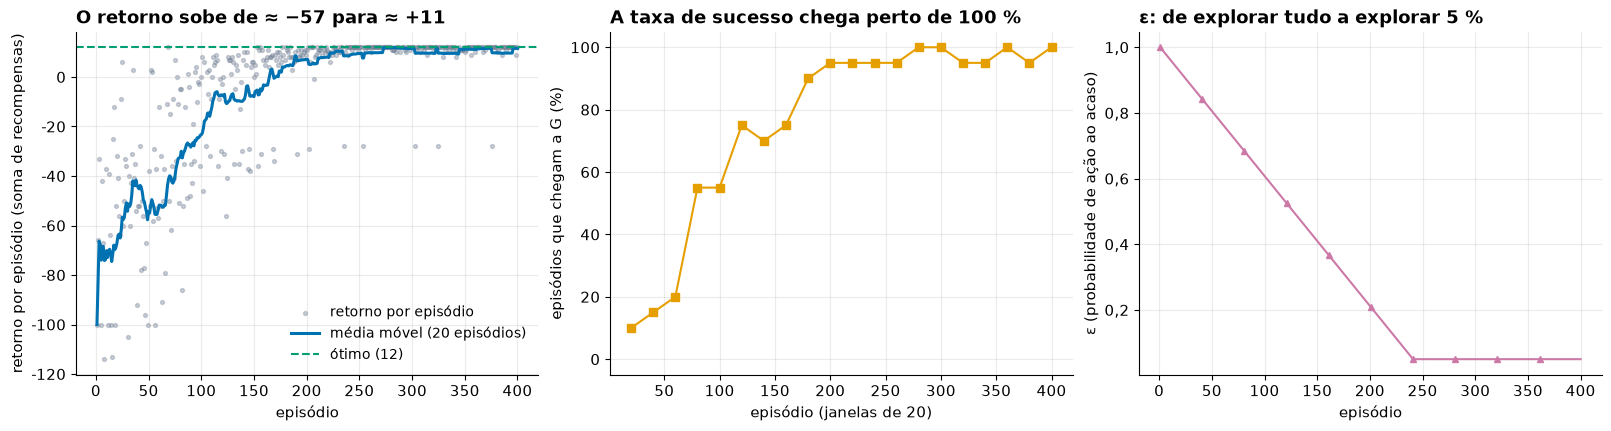

In [9]:
eps = np.array(hist["epsilon"])
ma = moving_average(returns, 20)
win = 20
succ_w = success.reshape(-1, win).mean(axis=1)
x_w = np.arange(win, 401, win)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), layout="constrained")
axes[0].scatter(range(1, 401), returns, s=8, alpha=0.35, color=PALETTE["grey"], label="retorno por episódio")
axes[0].plot(range(1, 401), ma, color=PALETTE["blue"], lw=2.2, label="média móvel (20 episódios)")
axes[0].axhline(12, color=PALETTE["green"], ls="--", label="ótimo (12)")
axes[0].set(title="O retorno sobe de ≈ −57 para ≈ +11", xlabel="episódio", ylabel="retorno por episódio (soma de recompensas)"); axes[0].legend(fontsize=10)
axes[1].plot(x_w, succ_w * 100, marker="s", color=PALETTE["orange"])
axes[1].set(title="A taxa de sucesso chega perto de 100 %", xlabel="episódio (janelas de 20)", ylabel="episódios que chegam a G (%)", ylim=(-5, 105))
axes[2].plot(range(1, 401), eps, color=PALETTE["purple"], marker="^", markevery=40, ms=5)
axes[2].set(title="ε: de explorar tudo a explorar 5 %", xlabel="episódio", ylabel="ε (probabilidade de ação ao acaso)")
finish(fig); plt.show()

### Avaliação greedy, em várias seeds, e com chão escorregadio

Treinamos 3 agentes (seeds 0, 1, 2) e avaliamos cada um com ε = 0 em `GridWorld()` e com `slip=0.1` (200 episódios, seed 123 no ambiente).

In [10]:
rows = []
q_by_seed = {}
for s in (0, 1, 2):
    Qs, h = q_learning(GridWorld(), episodes=400, seed=s)
    q_by_seed[s] = Qs
    ev = evaluate(GridWorld(), Qs, episodes=100)
    ev_slip = evaluate(GridWorld(slip=0.1, seed=123), Qs, episodes=200)
    r = np.array(h["return"]); ok = np.array([o == "goal" for o in h["outcome"]])
    rows.append({"seed": s, "retorno treino (1.º–50.º)": round(r[:50].mean(), 1), "retorno treino (últimos 50)": round(r[-50:].mean(), 1),
                 "sucesso treino (últimos 50)": f"{ok[-50:].mean():.0%}",
                 "greedy: retorno": round(ev["mean_return"], 1), "greedy: sucesso": f"{ev['success_rate']:.0%}", "greedy: passos": round(ev["mean_length"], 1),
                 "slip 0,1: retorno": round(ev_slip["mean_return"], 1), "slip 0,1: sucesso": f"{ev_slip['success_rate']:.0%}"})
pd.DataFrame(rows).set_index("seed").T

seed,0,1,2
retorno treino (1.º–50.º),-57.5,-53.8,-48.2
retorno treino (últimos 50),10.8,10.8,10.7
sucesso treino (últimos 50),98%,98%,98%
greedy: retorno,12.0,12.0,12.0
greedy: sucesso,100%,100%,100%
greedy: passos,9.0,9.0,9.0
"slip 0,1: retorno",9.9,10.2,10.0
"slip 0,1: sucesso",97%,98%,97%


Lê a tabela assim:

- **Treino:** o retorno dos primeiros 50 episódios (≈ −57,5; −53,8; −48,2) mostra o custo de explorar. Os últimos 50 ficam em ≈ 10,8, abaixo de 12 porque ε = 0,05 ainda faz alguns passos ao acaso.
- **Greedy (ε = 0):** retorno **12**, sucesso **100 %**, **9 passos**: é o ótimo possível (8 × (−1) + 20). Com seeds diferentes o resultado é igual, sinal de que o resultado não é sorte.
- **`slip=0.1`:** com 10 % de ações aleatórias, o sucesso baixa (≈ 97 %) e o retorno também (≈ 9,9): o agente foi treinado num mundo determinístico e agora é testado num mundo diferente.

### 💬 Discussão — Avaliação: treino vs avaliação

No treino, o retorno dos últimos 50 episódios foi ≈ 10,8; na avaliação greedy foi 12. Porquê a diferença? Qual dos dois números reportarias a um cliente?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

No treino o agente ainda explora com ε = 0,05, ou seja, em ≈ 1 passo em 20 age ao acaso, o que custa alguns passos e, por vezes, uma queda na lava: o retorno desce para ≈ 10,8 e o sucesso para 98 %. Na avaliação greedy (ε = 0) a política corre limpa: 12 e 100 %. Para o cliente reporta-se a avaliação **separada do treino** e **com as condições de uso** (por exemplo, `slip=0.1`: 97 % de sucesso e retorno ≈ 9,9), porque é isso que ele vai ver.
</details>

### O caminho greedy

A política treinada leva o agente de S a G pelo caminho mais curto: sobe pela coluna da esquerda e segue pela linha de cima.

caminho (linha, coluna): [(4, 0), (3, 0), (2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5)]
passos: 9 | retorno: 12


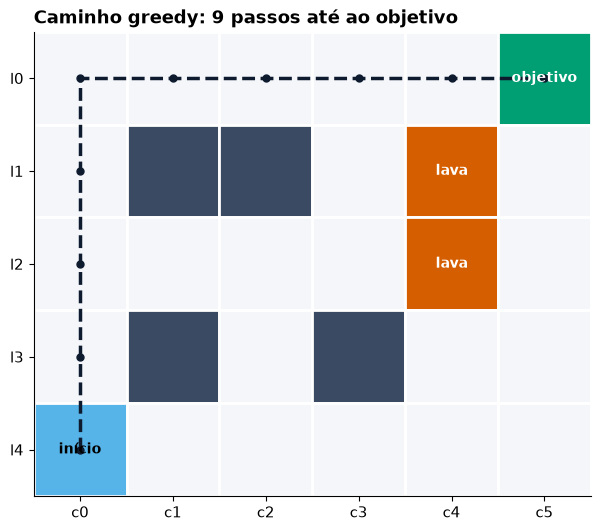

In [11]:
path = greedy_path(GridWorld(), Q)
rows_cols = [divmod(s, env.n_cols) for s in path]
print("caminho (linha, coluna):", rows_cols)
print(f"passos: {len(path) - 1} | retorno: {-(len(path) - 2) + 20}")

fig, ax = plt.subplots(figsize=(6.5, 5.2), layout="constrained")
draw_map(GridWorld(), ax, "Caminho greedy: 9 passos até ao objetivo", path=path)
finish(fig); plt.show()

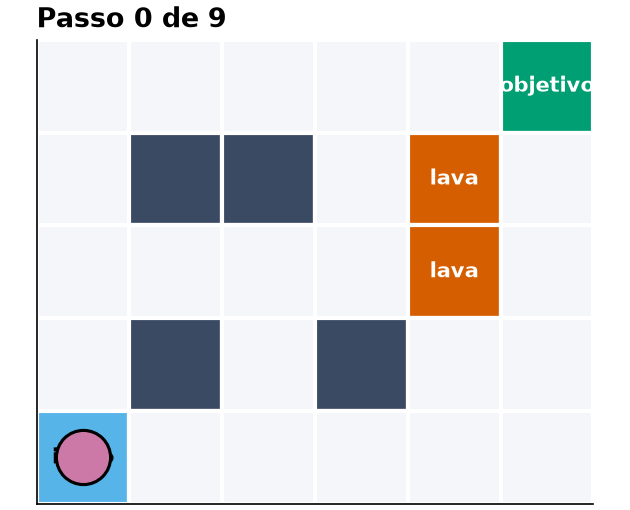

In [12]:
# GIF leve do agente treinado a percorrer o caminho (matplotlib + PillowWriter)
from matplotlib.animation import FuncAnimation, PillowWriter

import tempfile
from pathlib import Path

gif_path = Path(tempfile.gettempdir()) / "agent_path.gif"  # ficheiro temporário: não fica no repositório
fig, ax = plt.subplots(figsize=(4.2, 3.4), dpi=70, layout="constrained")
walker = GridWorld()

def frame(i):
    ax.clear()
    draw_map(walker, ax, f"Passo {i} de {len(path) - 1}", path=path[: i + 1], agent=path[i])
    ax.set_xticks([]); ax.set_yticks([])

anim = FuncAnimation(fig, frame, frames=len(path), interval=500)
anim.save(gif_path, writer=PillowWriter(fps=2))
plt.close(fig)
display(Image(filename=str(gif_path)))

<a id="sec-6"></a>

# 6. 🚀 Deployment e limites: reward hacking e shaping

Antes de pôr um agente a trabalhar, pergunta: **e se ele encontrar um atalho?** Usamos o `COIN_LAYOUT`: o mesmo mapa, mas com uma **moeda** (+5) em (4, 2), no caminho. Detalhe do ambiente: a moeda **nunca desaparece**, por isso pode ser recolhida uma e outra vez.

avaliação greedy (COIN_LAYOUT): retorno = 494 | sucesso = 0% | passos = 100
estados visitados nos 6 primeiros passos: [(4, 0), (4, 1), (4, 2), (4, 2), (4, 2), (4, 2)] …


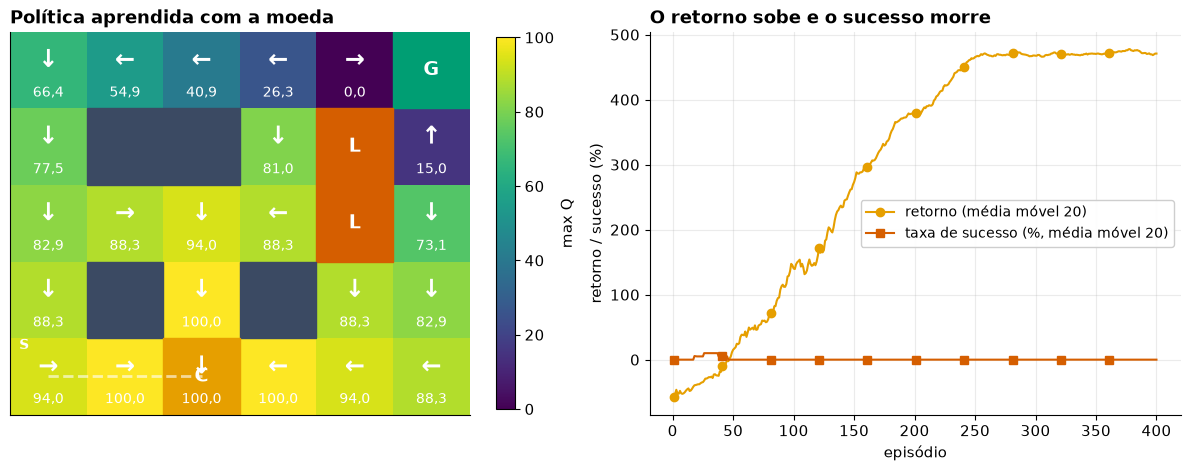

In [13]:
coin_env = GridWorld(layout=COIN_LAYOUT)
Qc, hist_c = q_learning(GridWorld(layout=COIN_LAYOUT), episodes=400, seed=0)
ev_c = evaluate(GridWorld(layout=COIN_LAYOUT), Qc, episodes=1)
path_c = greedy_path(GridWorld(layout=COIN_LAYOUT), Qc, max_steps=100)
print(f"avaliação greedy (COIN_LAYOUT): retorno = {ev_c['mean_return']:.0f} | sucesso = {ev_c['success_rate']:.0%} | passos = {ev_c['mean_length']:.0f}")
print("estados visitados nos 6 primeiros passos:", [divmod(s, env.n_cols) for s in path_c[:6]], "…")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), layout="constrained")
plot_q_values(coin_env, Qc, ax=axes[0], title="Política aprendida com a moeda", path=path_c[:12])
axes[1].plot(range(1, 401), moving_average(hist_c["return"], 20), marker="o", markevery=40, color=PALETTE["orange"], label="retorno (média móvel 20)")
ok_c = np.array([o == "goal" for o in hist_c["outcome"]], dtype=float)
axes[1].plot(range(1, 401), moving_average(ok_c * 100, 20), marker="s", markevery=40, color=PALETTE["red"], label="taxa de sucesso (%, média móvel 20)")
axes[1].set(title="O retorno sobe e o sucesso morre", xlabel="episódio", ylabel="retorno / sucesso (%)"); axes[1].legend(fontsize=10, loc="center right", frameon=True, facecolor="white", framealpha=0.95)
finish(fig); plt.show()

O agente descobriu que o **melhor retorno** é ficar em cima da moeda (+5 por passo) a bater na parede de baixo, e **nunca** ir ao objetivo. Retorno de avaliação **494** (100 passos × ≈ 5 menos custos), sucesso **0 %**. Matematicamente fez o que lhe pedimos; só que não é o que queríamos. É o **reward hacking** (ou *specification gaming*).

### Duas respostas

1. **Corrigir a especificação:** a moeda desaparece depois de recolhida (`OneShotCoinWorld` abaixo). Agora recolher a moeda uma vez **compensa** e ir ao objetivo continua a ser o fim.
2. ***Reward shaping* por potencial** (Ng, Harada & Russell, 1999): somar à recompensa $F = \gamma\,\Phi(s') - \Phi(s)$, em que $\Phi$ é um "potencial" (aqui, a distância de Manhattan ao objetivo, com sinal negativo). Dá pistas ao agente **sem alterar a política ótima**: só acelera a aprendizagem. Mas atenção: como **não altera** a política ótima, também **não corrige** um buraco na especificação.

In [14]:
class OneShotCoinWorld(GridWorld):
    """Como GridWorld, mas a moeda desaparece depois de recolhida (uma vez por episódio)."""
    def reset(self):
        self.grid = np.array([list(row) for row in self.layout])
        return super().reset()

    def step(self, action):
        out = super().step(action)
        r, c = divmod(self.state, self.n_cols)
        if self.grid[r, c] == "C":
            self.grid[r, c] = "."
        return out


class ShapedGridWorld(GridWorld):
    """Reward shaping por potencial: r' = r + γ·Φ(s') − Φ(s), com Φ = −distância de Manhattan a G (Φ = 0 nos terminais)."""
    def potential(self, state, terminal=False):
        if terminal:
            return 0.0
        (r, c), (gr, gc) = divmod(state, self.n_cols), divmod(self._find("G"), self.n_cols)
        return -float(abs(r - gr) + abs(c - gc))

    def step(self, action):
        s = self.state
        s2, r, done, outcome = super().step(action)
        bonus = gamma * self.potential(s2, outcome in ("goal", "lava")) - self.potential(s)
        return s2, r + bonus, done, outcome


def success_curve(make_env, seeds=range(5), episodes=400, win=20):
    """Taxa de sucesso por janela de episódios, média de várias seeds."""
    curves = []
    for s in seeds:
        _, h = q_learning(make_env(), episodes=episodes, seed=s)
        ok = np.array([o == "goal" for o in h["outcome"]], dtype=float)
        curves.append(ok.reshape(-1, win).mean(axis=1))
    return np.mean(curves, axis=0)

# 1) moeda que desaparece
Qo, _ = q_learning(OneShotCoinWorld(layout=COIN_LAYOUT), episodes=400, seed=0)
ev_o = evaluate(OneShotCoinWorld(layout=COIN_LAYOUT), Qo, episodes=1)
print(f"moeda que desaparece: retorno {ev_o['mean_return']:.0f}, sucesso {ev_o['success_rate']:.0%}, {ev_o['mean_length']:.0f} passos (12 do caminho ótimo + 6 pela moeda, que vale +5 em vez de −1)")

# 2) shaping por potencial: (a) acelera? (b) corrige o hack?
plain, shaped = success_curve(GridWorld), success_curve(ShapedGridWorld)
Qs_coin, _ = q_learning(ShapedGridWorld(layout=COIN_LAYOUT), episodes=400, seed=0)
ev_sc = evaluate(GridWorld(layout=COIN_LAYOUT), Qs_coin, episodes=1)
print(f"shaping + moeda eterna: retorno {ev_sc['mean_return']:.0f}, sucesso {ev_sc['success_rate']:.0%} -> o hack mantém-se")

moeda que desaparece: retorno 18, sucesso 100%, 9 passos (12 do caminho ótimo + 6 pela moeda, que vale +5 em vez de −1)


shaping + moeda eterna: retorno 494, sucesso 0% -> o hack mantém-se


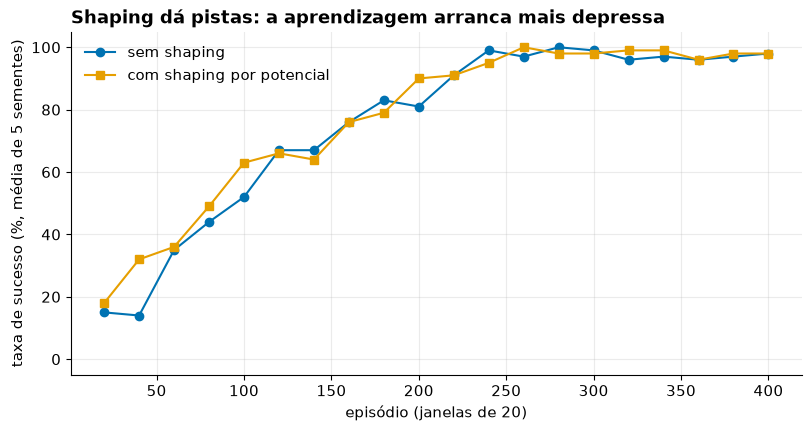

sucesso médio nas primeiras 5 janelas (episódios 1–100): sem shaping 32 % | com shaping 40 %


In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
x_w = np.arange(20, 401, 20)
ax.plot(x_w, plain * 100, marker="o", color=PALETTE["blue"], label="sem shaping")
ax.plot(x_w, shaped * 100, marker="s", color=PALETTE["orange"], label="com shaping por potencial")
ax.set(title="Shaping dá pistas: a aprendizagem arranca mais depressa", xlabel="episódio (janelas de 20)",
       ylabel="taxa de sucesso (%, média de 5 sementes)", ylim=(-5, 105)); ax.legend()
finish(fig); plt.show()
print("sucesso médio nas primeiras 5 janelas (episódios 1–100): sem shaping %.0f %% | com shaping %.0f %%" % (plain[:5].mean() * 100, shaped[:5].mean() * 100))

### 💬 Discussão — Reward hacking: de quem é a culpa?

O agente maximizou exatamente a recompensa que definimos. Quem errou? Dá dois exemplos reais em que "o que se mede" deixou de ser "o que se quer", e diz que verificação automática porias antes de pôr o agente em produção.

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Errou a **especificação**, não o algoritmo: a moeda eterna valia mais do que o objetivo (retorno de avaliação 494 vs 12, sucesso 0 %). Exemplos reais: um sistema de recomendação que maximiza o tempo no ecrã (e não a satisfação); um robô de limpeza que tapa o sensor de sujidade. Verificações: medir **sempre** o indicador de negócio (taxa de sucesso) à parte do retorno; correr cenários adversariais e de *stress* (como `slip`); inspecionar **trajetórias**, não só médias (o caminho preso na moeda salta à vista); e rever a função de recompensa com quem conhece o problema.
</details>

> ⚠️ **Cuidado:** o *reward shaping* por potencial **preserva** a política ótima (Ng et al., 1999), mas é fácil estragar essa garantia com bónus ad hoc, como "+1 por cada passo na direção certa" sem o termo $-\Phi(s)$: a moeda eterna é exatamente esse erro.

<a id="sec-7"></a>

# 7. 🔭 Extensões

### SARSA: a diferença de uma linha

O Q-learning é ***off-policy***: o alvo usa o **melhor** movimento seguinte, $\max_{a'} Q(s',a')$, mesmo que o agente (por ε) vá fazer outro. O **SARSA** é ***on-policy***: o alvo usa a ação $a'$ que o agente **vai mesmo fazer**.

In [16]:
def sarsa(env, episodes=400, alpha=0.5, gamma=0.95, eps_start=1.0, eps_end=0.05, decay_frac=0.6, seed=0):
    """Igual ao q_learning, mas o alvo usa a ação que o agente vai realmente escolher a seguir."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, env.n_actions))
    pick = lambda s, e: int(rng.integers(env.n_actions)) if rng.random() < e else int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))
    for ep in range(episodes):
        e = epsilon_schedule(ep, episodes, eps_start, eps_end, decay_frac)
        s, done = env.reset(), False
        a = pick(s, e)
        while not done:
            s2, r, done, outcome = env.step(a)
            a2 = pick(s2, e)
            terminal = outcome in ("goal", "lava")
            target = r if terminal else r + gamma * Q[s2, a2]      # ← única diferença: Q[s2, a2] em vez de Q[s2].max()
            Q[s, a] += alpha * (target - Q[s, a])
            s, a = s2, a2
    return Q

Q_sarsa = sarsa(GridWorld())
print("SARSA, avaliação greedy:", {k: round(v, 2) for k, v in evaluate(GridWorld(), Q_sarsa, 100).items()})
print("caminho SARSA:", [divmod(s, 6) for s in greedy_path(GridWorld(), Q_sarsa)])

SARSA, avaliação greedy: {'mean_return': 12.0, 'success_rate': 1.0, 'mean_length': 9.0}
caminho SARSA: [(4, 0), (3, 0), (2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5)]


Neste mundo pequeno, as duas chegam a políticas boas. Em mundos com precipícios, o SARSA tende a aprender caminhos mais **seguros** (porque conta com o ε que ainda explora), e o Q-learning, caminhos mais curtos e arriscados.

### E depois da tabela?

- **DQN**: quando há milhões de estados (imagem de um jogo), a tabela $Q$ é substituída por uma rede neuronal (notebook 04).
- **Políticas diretas, como o PPO**: em vez de aprender $Q$ e deduzir a política, aprendem a política com gradiente (usado, por exemplo, no ajuste de modelos de linguagem com *feedback* humano).
- **CartPole** (biblioteca Gymnasium): o "olá mundo" do RL contínuo, bom próximo passo. Fica como ponte; não é feito aqui.

<a id="sec-8"></a>

# 8. ✏️ Exercícios

### ✏️ Exercício 1 — O efeito de γ

**Dificuldade:** ⭐⭐

Treina o Q-learning com γ = 0,5 e γ = 0,99 (400 episódios, seed 0). Avalia em modo greedy e mostra o caminho. A política muda? E os valores de Q na partida? (Dica: `q_learning(..., gamma=...)`.)

In [17]:
# TODO

<details>
<summary>💡 Ver solução</summary>

Neste mapa a política é a mesma nos dois casos (retorno de avaliação 12, 9 passos): como só há um objetivo e o custo por passo é constante, valer menos ou mais ao longe não altera a ordem das ações. O que muda é a **escala de Q**: com γ = 0,5 o valor do estado inicial é negativo e com γ = 0,99 é ≈ 10,7. γ só altera a política quando há compromissos entre recompensas próximas e distantes (por exemplo, uma moeda perto e um objetivo longe).

```python
for g in (0.5, 0.99):
    Qg, _ = q_learning(GridWorld(), episodes=400, gamma=g, seed=0)
    print(g, evaluate(GridWorld(), Qg, 1), len(greedy_path(GridWorld(), Qg)) - 1, 'passos')
```
</details>

### ✏️ Exercício 2 — Treinar com chão escorregadio

**Dificuldade:** ⭐⭐

Treina com `GridWorld(slip=0.1, seed=1)` e avalia em `GridWorld(slip=0.1, seed=123)` (200 episódios). O agente treinado **no** ruído é melhor do que o treinado sem ruído (97 % de sucesso)? Compara o caminho e a taxa de sucesso.

In [18]:
# TODO

<details>
<summary>💡 Ver solução</summary>

Neste mapa, não: o resultado é idêntico (97 % de sucesso, retorno ≈ 9,9) e o caminho é o mesmo, porque a rota pela coluna da esquerda e linha de cima já está longe da lava. Treinar no ambiente de uso costuma ajudar mais quando há perigos perto do caminho curto, onde o agente aprende a manter distância; aqui o mapa não o exige.

```python
Qn, _ = q_learning(GridWorld(slip=0.1, seed=1), episodes=400, seed=0)
print(evaluate(GridWorld(slip=0.1, seed=123), Qn, 200))
print([divmod(s, 6) for s in greedy_path(GridWorld(), Qn)])
```
</details>

### ✏️ Exercício 3 — Conserta o hack à tua maneira

**Dificuldade:** ⭐⭐⭐

Em vez de a moeda desaparecer, muda **a recompensa** da moeda no `GridWorld(layout=COIN_LAYOUT, coin_reward=...)`. A partir de que valor de `coin_reward` o agente deixa de ir ao objetivo? (Procura com um ciclo: −1, 0, 0,25, 0,5, 1, 2, 5.) Porque é calibrar este número uma solução frágil?

In [19]:
# TODO: for cr in (-1, 0, 0.25, 0.5, 1, 2, 5): ...

<details>
<summary>💡 Ver solução</summary>

O limiar está entre 0,25 (sucesso 100 %, retorno 13,25) e 0,5 (sucesso 0 %): ficar parado na moeda vale `coin_reward`/(1 − γ) = 20 × `coin_reward`, que ultrapassa o valor do caminho até G quando `coin_reward` passa de ≈ 0,3. É um limiar que depende de γ, do custo do passo e do mapa: frágil. A solução robusta é **mudar o desenho** (a moeda desaparece) e verificar sempre com a taxa de sucesso.

```python
for cr in (-1, 0, 0.25, 0.5, 1, 2, 5):
    Qx, _ = q_learning(GridWorld(layout=COIN_LAYOUT, coin_reward=cr), episodes=400, seed=0)
    print(cr, evaluate(GridWorld(layout=COIN_LAYOUT, coin_reward=cr), Qx, 1))
```
</details>

<a id="sec-9"></a>

# 9. 📌 Resumo

| Ideia | Em uma linha |
|---|---|
| **MDP** | estados, ações, transições, recompensas e desconto γ; futuro depende só do estado atual |
| **Retorno** | $G_t=\sum\gamma^k r_{t+k+1}$; com γ = 0,95 o caminho ótimo vale ≈ 6,5 visto da partida |
| **Q-learning** | $Q\leftarrow Q+\alpha[r+\gamma\max Q(s',\cdot)-Q]$; 1.ª atualização à mão: Q(4,→) = 10, Q(3,→) = 4,25 |
| **ε-greedy** | explora com prob. ε (1,0 → 0,05); evita ficar preso ao que parece bom |
| **Avaliação** | greedy (ε = 0), separada do treino, várias seeds: 12 de retorno, 100 % de sucesso, 9 passos |
| **Robustez** | com `slip=0.1`: sucesso ≈ 97 %, retorno ≈ 9,9 |
| **Reward hacking** | moeda eterna: retorno 494 e sucesso 0 %; medir sempre o indicador real |
| **Shaping** | $F=\gamma\Phi(s')-\Phi(s)$ acelera sem mudar a política ótima, mas não corrige uma especificação errada |

**Checklist:** ☐ defini o que é sucesso (além do retorno)? ☐ avaliei com ε = 0 e noutras seeds? ☐ testei com ruído? ☐ vi o caminho do agente? ☐ procurei atalhos na recompensa?

<a id="sec-10"></a>

# 10. 📚 Para saber mais

- Sutton, R. S. & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2.ª ed.), MIT Press: <http://incompleteideas.net/book/the-book-2nd.html> (cap. 3, MDP; cap. 6, Q-learning e SARSA; §17.4, desenho de recompensas).
- Ng, A., Harada, D. & Russell, S. (1999). *Policy invariance under reward transformations: theory and application to reward shaping*. ICML.
- Gymnasium (CartPole e outros ambientes): <https://gymnasium.farama.org>.
- Chapman et al. (2000). *CRISP-DM 1.0*. SPSS/NCR/DaimlerChrysler.

---
<div align="center">

⬅️ [Anterior: 04 · Redes neuronais do zero](../../03_neural_networks/notebooks/04_Neural_Networks_From_Scratch.ipynb) &nbsp;·&nbsp; 🏠 [Lição 02](../../README.md)

**The AI Learning Hub** · Lição 02 — Machine Learning: fundamentos<br>
Diogo Freitas & João Francisco Botas · Licença MIT

</div>